In [2]:
%load_ext autoreload
%autoreload 2
import json
import os
import sys
sys.path.insert(0, os.path.abspath('../'))
import ResParTools as pt
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. SMILES → имена атомов и заряды

На входе только модифицированный мономер. Все сопоставления и заряды сохраняются в свойствах RDKit;
между ноутбуками остаток передаётся через SDF. Автоматически найденный структурный родитель может
отличаться от химического родителя модификации: проверьте список кандидатов и картинку шага 3.

In [3]:
# Параметры модификации (сгенерировано для этой папки)
FOLDER = 'Lysine_Malonyl'
PTM_name = 'Lysine_Malonyl'
base_name = 'KML'
monomer_file = 'molecules/Lysine_malonyl.smiles'
naming = 'greek'
parent_override = None  # None - выбрать по сопоставлению; иначе имя шаблона, например 'LYS'
run_resp_now = False
OUT = os.path.abspath(os.path.join('..', 'build', 'notebooks', FOLDER))
os.makedirs(OUT, exist_ok=True)

## Шаг 1. Прочитать модифицированный мономер

Мономер задаёт химический граф и стереохимию. Тример пользователя не нужен.

Загрузка файла: Lysine_malonyl (формат: .smiles)
Lysine_malonyl: 30 атомов; формальный заряд -1


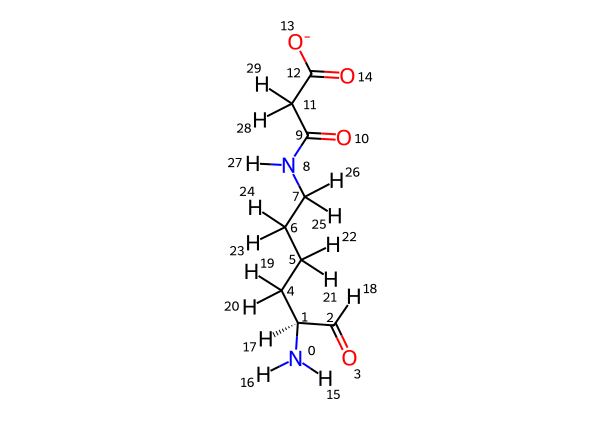

In [4]:
monomer = pt.open_mol(monomer_file)
mon_name = monomer.GetProp('ModName')
print(f'{mon_name}: {monomer.GetNumAtoms()} атомов; формальный заряд {Chem.GetFormalCharge(monomer):+d}')
pt.draw_molecule(monomer, show_index=True)

## Шаг 2. Найти структурного родителя

Сопоставление выполняется со всеми кэпированными шаблонами. Рейтинг — число атомов общей
подструктуры; при равенстве программа выбирает первый шаблон в порядке имён файлов. Это структурная
подсказка, а не химическое заключение. При необходимости задайте `parent_override` по точному имени
кандидата.

In [5]:
ref_dict, match_data, auto_ref = pt.find_ref_residue(
    {'residue': monomer}, residue_type='protein_capped', main_match_data=False,
    timeout=3, strict_parent=False)
scores = match_data['N_match_atoms']
ranked = sorted(scores.items(), key=lambda item: (-item[1], item[0]))
for ref_name, n_atoms in ranked:
    print(f'{ref_name:5s}  общих атомов: {n_atoms}')

if parent_override is None:
    selected_ref = auto_ref
else:
    if parent_override not in scores:
        raise ValueError(f'{parent_override!r} отсутствует среди кандидатов: {sorted(scores)}')
    selected_ref = parent_override
print(f'⚠ Выбран структурный кандидат {selected_ref}; проверьте, что это химический родитель.')

⚠ Родительский остаток не указан (ref_base_name): выбран будет структурный кандидат с наибольшим совпадением. Он может не совпадать с химическим родителем модификации; проверьте список кандидатов и при необходимости задайте точное имя шаблона, например ref_base_name='LYS'.
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно

## Шаг 3. Перенумерация и имена атомов

Канонические атомы получают имена из выбранного шаблона; новые атомы модификации — по выбранной
схеме именования. Общие атомы для подсветки берутся из сохранённой карты `ParentName`.

In [6]:
ref_path = os.path.join(pt.REF_TEMPLATES['protein_capped']['dir'], f'{selected_ref}.pdb')
residue = pt.renumber_residue_atoms(
    monomer, ref_base_name=selected_ref, residue_type='protein_capped',
    path_to_ref_mol=ref_path, timeout=3, strict_parent=False)
parent_atoms = json.loads(residue.GetProp('ParentAtoms'))
residue = pt.rdkit_pdb_modification(residue, resname=base_name, resid=2, segid='A',
                                    naming=naming, parent_atoms=parent_atoms)

Выполнение Поиск подструктуры между молекулами.  
Поиск подструктуры между молекулами выполнен успешно!
Родительский остаток: лизин (Lys, K), шаблон LYN; сопоставлено атомов: 20.
Перенумеровано атомов: 29 из 30 (канонических: 20)
Имена атомов (буквенный способ): N H1 H2 CA HA CB HB1 HB2 CG HG1 HG2 CD HD1 HD2 CE HE1 HE2 NZ HZ CH OT1 CT2 HT21 HT22 CI OK1 OK2 C H O


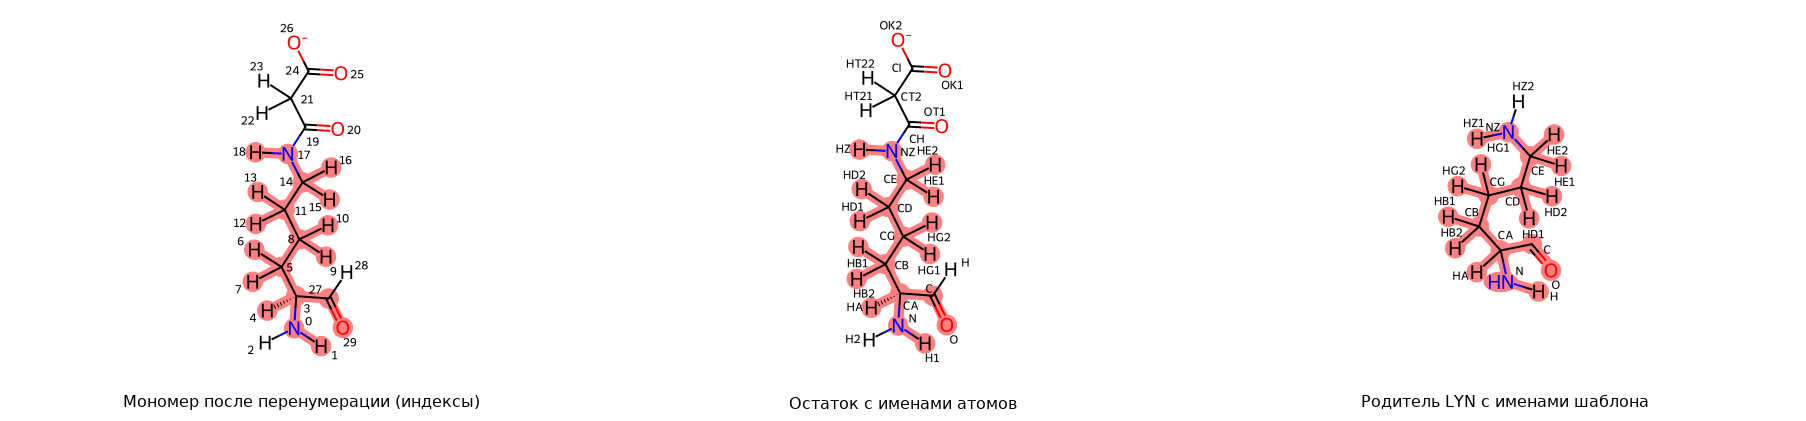

In [7]:
# Общая карта строится по ParentName, а не по совпавшим локальным индексам.
shared_residue = [a.GetIdx() for a in residue.GetAtoms() if a.HasProp('ParentName')]
shared_names = [residue.GetAtomWithIdx(i).GetProp('ParentName') for i in shared_residue]

template = pt.pdb_to_chem(ref_path, format_coord='3D')
if isinstance(template, dict):
    template = template[selected_ref]
parent = pt.extract_residue(template, 2)
parent_idx = {a.GetProp('AtomName'): a.GetIdx() for a in parent.GetAtoms()}
missing = sorted(set(shared_names) - set(parent_idx))
if missing:
    raise ValueError(f'Имена общей подструктуры отсутствуют в шаблоне: {missing}')
shared_parent = [parent_idx[name] for name in shared_names]

pt.draw_mol_grid(
    [residue, residue, parent],
    legends=['Мономер после перенумерации (индексы)', 'Остаток с именами атомов',
             f'Родитель {selected_ref} с именами шаблона'],
    highlight_atoms=[shared_residue, shared_residue, shared_parent],
    show_index=[True, False, False], show_names=[False, True, True], mols_per_row=3)

## Шаг 4. Проверить и при необходимости поправить имена

`rename_map` — явное соответствие старого и нового имени. Имена проверяются на дубликаты до расчёта
зарядов.

In [ ]:
rename_map = {}
residue = pt.modifie_residue_info(residue, rename_map, resname=base_name, resid=2, segid='A')
duplicates = pt.check_duplicate_atom_names(residue)
if duplicates:
    raise ValueError(f'Повторяющиеся имена атомов: {duplicates}')
for atom in residue.GetAtoms():
    print(f"{atom.GetIdx():3d} {atom.GetProp('AtomName'):5s} "
          f"родитель: {atom.GetProp('ParentName') if atom.HasProp('ParentName') else '-'}")

### Шаг 4.1. Подготовить водороды и 3D для acpype

`AddedH` отмечает HW на концах остатка; эти атомы нужны для топологии/проверки и не меняют набор
атомов самого остатка.

In [ ]:
h_residue = pt.add_protons_and_renumber_H(residue, resname=base_name, resid=2, segid='A')
h_residue = pt.set_mol_coords(h_residue, coords='3D', ca_config='L')

## Шаг 5. Заряды Espaloma

Заряды N, H, CA, HA, C и O фиксируются по `aminoacids.rtp` выбранного родительского типа;
остальные рассчитывает Espaloma. После пользовательских ограничений сумма зарядов должна остаться
равной формальному заряду остатка.

In [ ]:
from espaloma_charge import charge

parent_code = residue.GetProp('Parent')
rtp_parent = pt.AMINO_ACIDS[parent_code][0].upper()
constraints = pt.charge_constraints_from_rtp(residue, rtp_parent)

# Пример: задать известный заряд отдельного атома по его индексу.
# constraints[residue.GetAtomWithIdx(atom_idx).GetIdx()] = -0.30
# Пример: зафиксировать одинаковый заряд на эквивалентных атомах (ограничение задаётся
# отдельно для каждого атома; это не ограничение только суммы группы).
# equivalent_atoms = [idx_1, idx_2]
# constraints.update({idx: -0.15 for idx in equivalent_atoms})

q = charge(residue, constraints=constraints)
pt.set_charges(residue, q, 'Espaloma', constraints)
total = float(q.sum())
formal = Chem.GetFormalCharge(residue)
print(f'Сумма зарядов: {total:+.5f}; формальный заряд: {formal:+d}')
if abs(total - formal) > 1e-3:
    raise ValueError('Сумма частичных зарядов не совпадает с формальным зарядом.')
pt.draw_molecule(residue, charge_list=q, show_names=True, show_index=False)

## Шаг 6. RESP (необязательно)

Подготовка сохраняет отдельные геометрии и контрольные точки. Для локального расчёта включите
`run_resp_now`; на кластере после проверки `spec.json` сгенерируйте SLURM-скрипт и отправьте его
командой `sbatch`. Здесь кластерная задача не отправляется автоматически.

In [ ]:
resp_folder = pt.prepare_resp_job(
    residue, constraints, f'{mon_name}_capped', working_dir=os.path.join(OUT, 'resp'),
    fix_backbone=True, n_sidechain=3, monomer=monomer)
print('Подготовлена RESP-задача:', resp_folder)

# Локально (долго):
if run_resp_now:
    q_resp = pt.run_resp(resp_folder, run='local', n_threads=4, n_parallel=1)
    pt.set_charges(residue, q_resp, 'RESP', constraints)
    print('Для следующего шага выбран RESP.')

# Кластер: сначала создать run_resp.sbatch; затем вручную отправить его через sbatch.
# slurm = {'cpus': 24, 'mem': '30G', 'time_limit': '08:00:00', 'partition': 'intbio'}
# pt.run_resp(resp_folder, run='slurm', slurm=slurm)
# В терминале: cd <путь resp_folder> && sbatch run_resp.sbatch
# После завершения: q_resp = pt.load_resp_result(resp_folder); pt.set_charges(residue, q_resp, 'RESP', constraints)

## Сохранить результат

Основной SDF содержит свойства атомов и молекулы; второй SDF включает водороды/3D для acpype.
Заряд Espaloma остаётся выбранным по умолчанию, пока не назначен RESP.

In [ ]:
sdf_path = pt.save_mol(residue, os.path.join(OUT, f'4_{mon_name}'))
h_sdf_path = pt.save_mol(h_residue, os.path.join(OUT, f'4_1_{mon_name}'))
print('Остаток:', sdf_path)
print('Остаток с H/3D для acpype:', h_sdf_path)